# **PROJETO STP - M5 Forescasting**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

# **Phase 1 - Statistical Models - AutoETS**

## **1. Imports and Data Upload**

In [ ]:
!pip install statsforecast #Instalar a biblioteca statsforecast

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.6/354.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 1.5 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


In [ ]:
from google.colab import files
import io

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from statsforecast import StatsForecast

from statsforecast.models import AutoETS

from sklearn import metrics

Tal como o método adotado no documento anterior carregamos os ficheiros com os dados das séries temporais escolhidas (departamento: *HOBBIES_2_TX1*) e o último ficheiro com os resultados dos *Baseline Models* e do *AutoARIMA*.

In [ ]:
uploaded = files.upload()

if 'HOBBIES_2_TX1.csv' in uploaded and 'Results_AutoARIMA.csv' in uploaded:
    Y_df_HOBBIES_2_TX1 = pd.read_csv(io.BytesIO(uploaded['HOBBIES_2_TX1.csv']), parse_dates=['ds'])
    AuroARIMA_results = pd.read_csv(io.BytesIO(uploaded['Results_AutoARIMA.csv']), sep=',')
    print("Both files uploaded successfully.")
else:
    print("Please ensure both 'HOBBIES_2_TX1.csv' and 'Results_AutoARIMA.csv' are uploaded.")

Y_df_HOBBIES_2_TX1

Saving HOBBIES_2_TX1.csv to HOBBIES_2_TX1.csv
Saving Results_AutoARIMA.csv to Results_AutoARIMA.csv
Both files uploaded successfully.


,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
train = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] <= '2016-05-22'] #Selecionar os dados anteriores aos últimos 28 dias de cada série
train

,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0


In [ ]:
test = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] > '2016-05-22'] #Selecionar os últimos 28 dias de cada série
test

,unique_id,ds,y
1928,HOBBIES_2_001_TX_1,2016-05-23,0.0
1929,HOBBIES_2_001_TX_1,2016-05-24,0.0
1930,HOBBIES_2_001_TX_1,2016-05-25,0.0
1931,HOBBIES_2_001_TX_1,2016-05-26,0.0
1932,HOBBIES_2_001_TX_1,2016-05-27,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
train.shape, test.shape

((217559, 3), (4172, 3))

A frequência dos dados disponibilizados, à semelhança dos documentos anteriores, continua a ser diária, com sazonalidade semanal (7 dias) e com o objetivo de prever os próximos 28 dias (horizon = 28). Com o objetivo de otimizar o desempenho do modelo os parâmetros "erro", "tendência" e "sazonalidade" são definidos como "*model = ["Z","Z","Z"]*", permitindo ao próprio modelo que selecione a melhor combinação.

In [ ]:
freq = 'D'
season_length = 7
horizon = 28

In [ ]:
sf = StatsForecast(
    models=[AutoETS(model=["Z","Z","Z"], alias="AutoETS", season_length=season_length)],
    freq=freq
)

In [ ]:
sf.fit(train)

StatsForecast(models=[AutoETS])

In [ ]:
fit_dict = sf.fitted_[0, 0].model_
fit_dict

{'loglik': -4310.9098372245435,
 'aic': 8627.819674449087,
 'bic': np.float64(8644.512389874599),
 'aicc': 8627.83214846156,
 'mse': np.float64(0.04539559051937264),
 'amse': np.float64(0.04509348447280862),
 'fit': results(x=array([0.00242437, 0.02970307]), fn=8621.819674449087, nit=42, simplex=array([[0.00242437, 0.02970307],
        [0.00242213, 0.02930281],
        [0.00244768, 0.02950198]])),
 'residuals': array([ 0.97029693, -0.03205543, -0.03197772, ..., -0.05481894,
        -0.05468604, -0.05455346]),
 'components': 'ANNN',
 'm': 1,
 'nstate': 1,
 'fitted': array([0.02970307, 0.03205543, 0.03197772, ..., 0.05481894, 0.05468604,
        0.05455346]),
 'states': array([[0.02970307],
        [0.03205543],
        [0.03197772],
        ...,
        [0.05468604],
        [0.05455346],
        [0.05442121]]),
 'par': array([0.00242437,        nan,        nan,        nan, 0.02970307]),
 'sigma2': np.float64(0.04548996804643988),
 'n_params': 3,
 'method': 'ETS(A,N,N)',
 'actual_residu

In [ ]:
print(fit_dict.get('method')) #Ver os parametros escolhidos pelo modelo

ETS(A,N,N)


Seguindo a ordem da sigla ETS (*Error*, *Trend* e *Seasonality*) o modelo assume que as séries não tem tendência nem sazonalidade.


O modelo ETS selecionou o componente A para a estrutura do erro, indicando que a série é melhor representada por um esquema de erro aditivo. Em termos práticos, o modelo assume que as flutuações em torno do valor ajustado têm uma magnitude semelhante em toda a série, o que é consistente com séries onde a amplitude das oscilações não aumenta nem diminui de forma proporcional ao valor observado. A escolha do erro aditivo é, portanto, coerente com o comportamento empírico da série e contribui para uma modelação mais estável e adequada.


In [ ]:
levels = [95]

forecasts = sf.predict(h=horizon, level=levels)

forecasts

,unique_id,ds,AutoETS,AutoETS-lo-95,AutoETS-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.054421,-0.363607,0.472450
1,HOBBIES_2_001_TX_1,2016-05-24,0.054421,-0.363609,0.472451
2,HOBBIES_2_001_TX_1,2016-05-25,0.054421,-0.363610,0.472452
3,HOBBIES_2_001_TX_1,2016-05-26,0.054421,-0.363611,0.472453
4,HOBBIES_2_001_TX_1,2016-05-27,0.054421,-0.363612,0.472455
...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.482171,-1.074316,2.038657
4168,HOBBIES_2_149_TX_1,2016-06-16,0.482171,-1.076707,2.041049
4169,HOBBIES_2_149_TX_1,2016-06-17,0.482171,-1.079095,2.043437
4170,HOBBIES_2_149_TX_1,2016-06-18,0.482171,-1.081479,2.045821


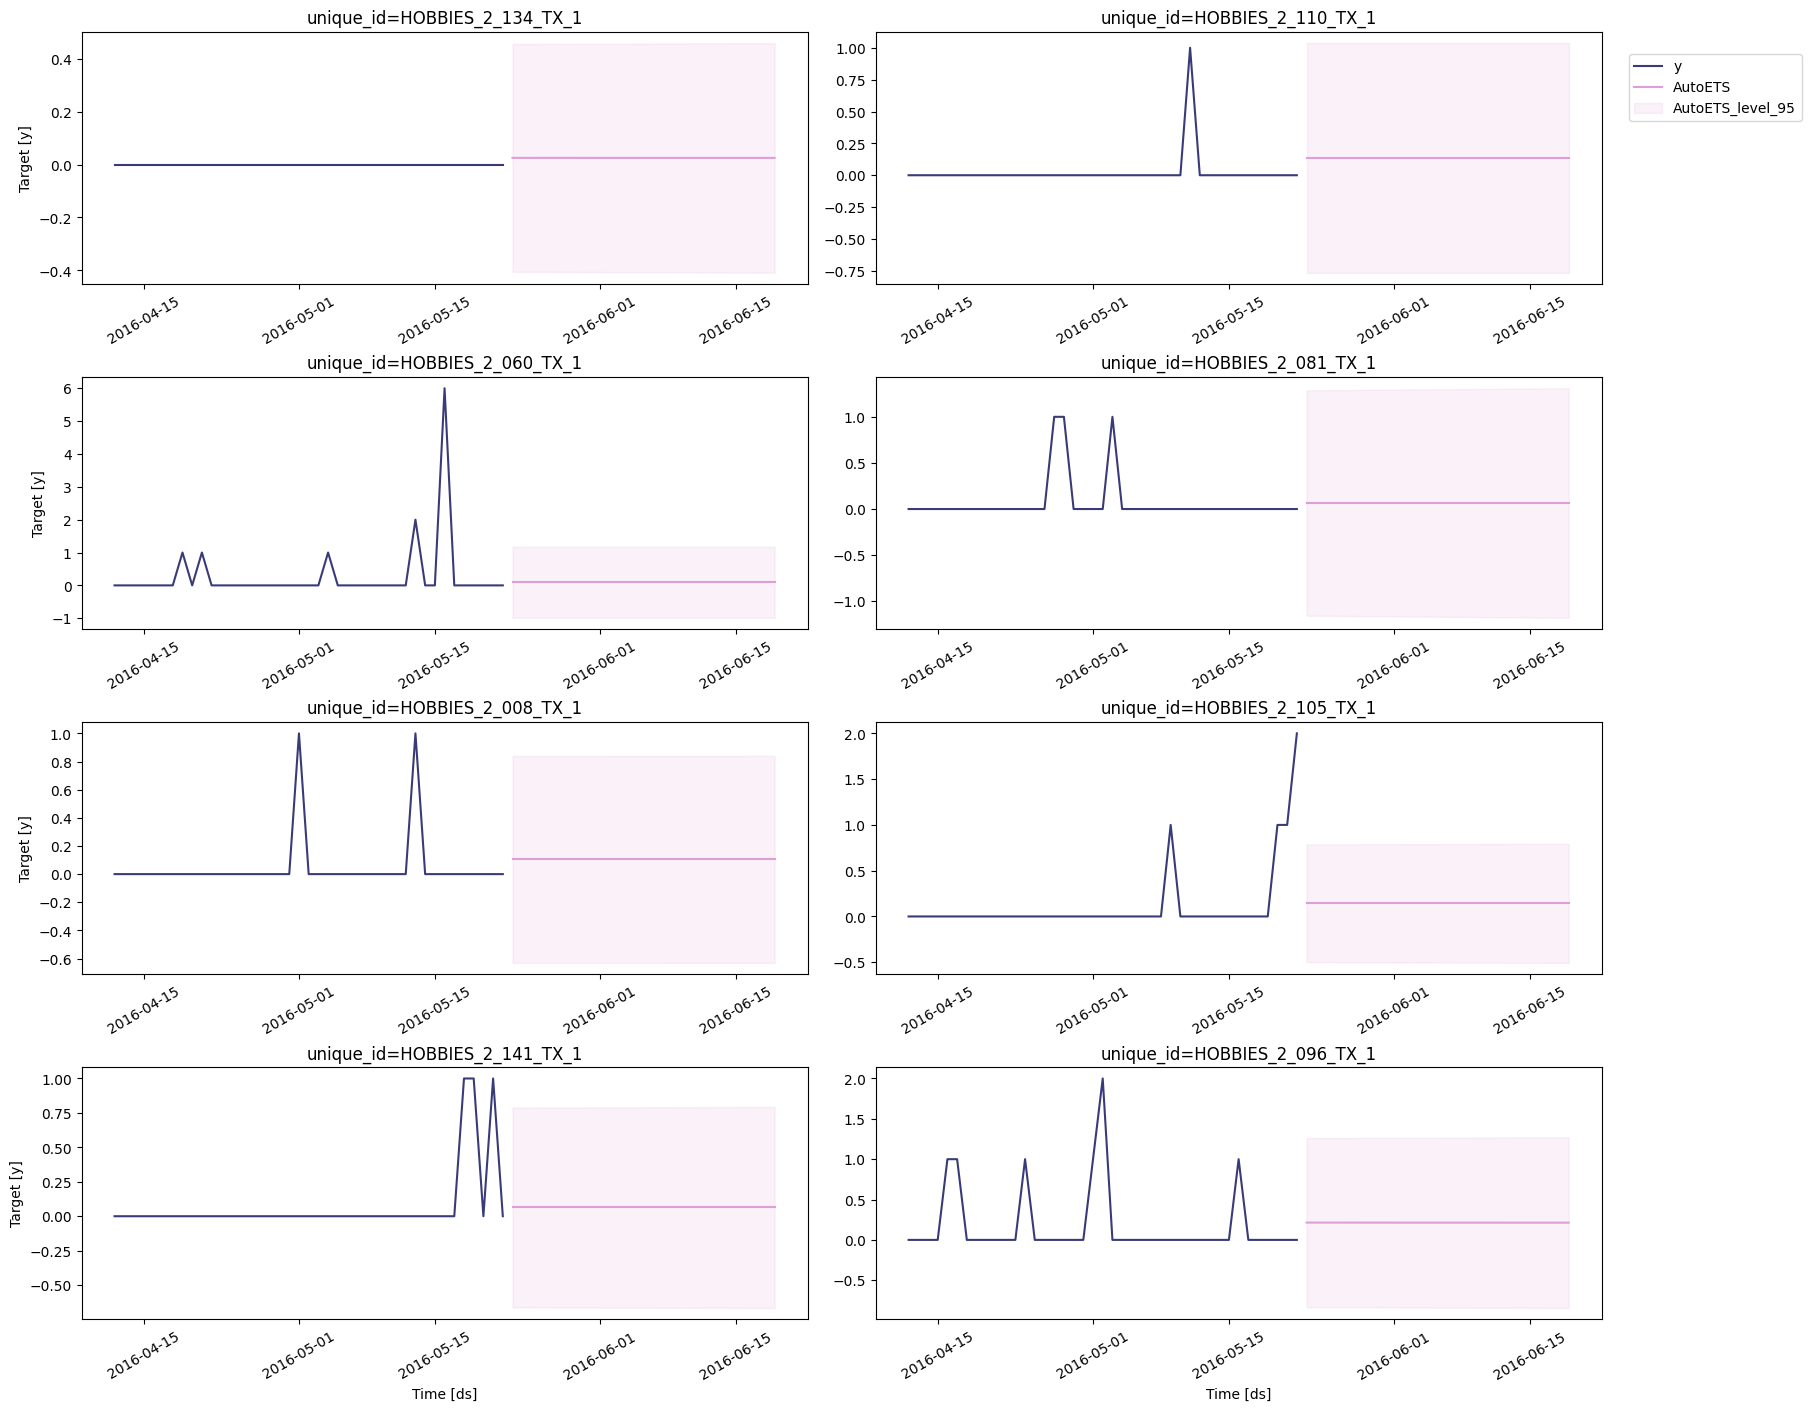

In [ ]:
cutoff = train["ds"].max() - pd.Timedelta(days=40)
train_last40 = train[train["ds"] >= cutoff]

sf.plot(train_last40, forecasts, level=levels)

In [ ]:
def rmsse(y, y_hat, y_train, seasonality):
    delta_y = np.mean((y - y_hat) ** 2)

    scale = np.mean((y_train[:-seasonality] - y_train[seasonality:]) ** 2)

    if scale < 1e-8:
        return np.nan

    return np.sqrt(delta_y / scale)


def mase(y, y_hat, y_train, seasonality):
    delta_y = np.mean(np.abs(y - y_hat))

    scale = np.mean(np.abs(y_train[:-seasonality] - y_train[seasonality:]))

    if scale < 1e-8:
        return np.nan

    return delta_y / scale


def model_evaluation(y_hist, y_true, y_pred, Model, seasonality):

    mse = metrics.mean_squared_error(y_true, y_pred)

    results_row = [{
        "Model": Model,
        "MSE": mse,
        "MAE": metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "RMSSE": rmsse(y_true.values, y_pred.values, y_hist.values, seasonality),
        "MASE": mase(y_true.values, y_pred.values, y_hist.values, seasonality)
    }]

    return pd.DataFrame(results_row)

In [ ]:
Models_results = pd.DataFrame()

new_result = model_evaluation(
    train["y"],
    test["y"],
    forecasts["AutoETS"],
    "AutoETS",
    season_length
)

Models_results = pd.concat([Models_results, new_result], ignore_index=True)

Final_results = pd.concat([AuroARIMA_results, Models_results], ignore_index=True)

Final_results.to_csv("Results_AutoETS.csv", index=False)

Final_results

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,Naive,1.093480,0.509588,1.045696,1.108525,1.559721
1,SeasonalNaive,1.131352,0.493768,1.063650,1.127558,1.511300
2,HistoricAverage,0.433728,0.342736,0.658580,0.698150,1.049029
3,RandomWalkWithDrift,1.105867,0.522300,1.051602,1.114786,1.598628
4,AutoARIMA,0.458665,0.373214,0.677248,0.717940,1.142315
5,AutoETS,0.469799,0.385673,0.685419,0.726601,1.180449


Com base nas métricas de desempenho apresentadas, verifica‑se que o modelo `HistoricAverage` evidencia um desempenho consistentemente superior face aos restantes modelos avaliados. Este modelo apresenta os valores mais baixos em todas as métricas de erro - MSE, MAE, RMSE, RMSSE e MASE - o que demonstra uma maior capacidade de representar o comportamento histórico da série e de produzir previsões mais precisas. Em comparação com modelos mais complexos, como o `AutoARIMA` ou o `AutoETS`, o `HistoricAverage` revela‑se mais eficaz no contexto específico dos dados analisados, destacando‑se como a solução mais robusta e fiável entre todas as alternativas consideradas.


